# SchNet-driven NVE dynamics: energy conservation by construction

<div style="background: rgba(33, 150, 243, 0.10); border-left: 4px solid #2196f3; padding: 0.6em 1em; margin: 0.8em 0; border-radius: 0 4px 4px 0;"> 

<b>Note:</b> Run <b>schnet_rmd17_train.ipynb</b> first as it
writes the <code>runs/schnet_rmd17/best.pt</code> checkpoint (saved by the
trainer's <code>ModelCheckpoint</code> callback) consumed by this notebook.
</div>

One of the central design claims of the [SchNet
manuscript](https://arxiv.org/pdf/1706.08566) is that predicting the energy and
differentiating it yields a **curl-free, energy-conserving force field**.
Combined with the infinitely differentiable shifted-softplus, this is one of the
key reasons making SchNet usable for molecular dynamics.

This notebook tests this claim: it loads the SchNet trained on rMD17 ethanol by
`schnet_rmd17_train.ipynb`, drives ASE **NVE**
(velocity-Verlet) dynamics with it through `XNNCalculator`, and checks whether
total energy is conserved while kinetic and potential energy exchange freely.

## 0. Load the trained SchNet and wrap it as an ASE calculator

In [1]:
import time
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import torch
import matplotlib.pyplot as plt

torch.manual_seed(0)
np.random.seed(0)

import xnn
from xnn.common.data import load_dataset
from xnn.common.deploy import XNNCalculator
from xnn.common.models.hub import load_pretrained

from ase import Atoms, units
from ase.md.velocitydistribution import (MaxwellBoltzmannDistribution,
                                         Stationary, ZeroRotation)
from ase.md.verlet import VelocityVerlet

In [2]:
# Set the device
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Load the best checkpoint of the training run: the model is rebuilt from the
# config stored with the weights and served in their dtype (float64)
CKPT = "runs/schnet_rmd17/best.pt"
loaded = load_pretrained(CKPT, device=DEVICE)

# Create the ASE calculator
calc = XNNCalculator(loaded.model, cutoff=loaded.cutoff, device=DEVICE)

# Print the model information
cfg = loaded.config.model
print(f"xnn {xnn.__version__} | loaded {CKPT} "
      f"(F={cfg.n_features}, T={cfg.n_interactions}, "
      f"cutoff={loaded.cutoff} A, {calc.dtype}) on {DEVICE}")

xnn 0.13.0 | loaded runs/schnet_rmd17/best.pt (F=64, T=3, cutoff=10.0 A, torch.float64) on cpu


## 1. NVE molecular dynamics of ethanol

We start from a held-out rMD17 conformation, draw 300 K Maxwell–Boltzmann
velocities, and integrate with velocity Verlet at a 0.5 fs time step (the
resolution of the reference trajectories in the [SchNet
 manuscript](https://arxiv.org/pdf/1706.08566)) for 2 ps. 
 
We do not use a thermostat so that in the NVE ensemble, any error in the forces
shows up directly as drift or noise in the total energy.

In [3]:
# Load the ethanol dataset
s = load_dataset("rmd17", molecule="ethanol", split="test", n_test=1,
                 quiet=True)[0]

# Initialize the ASE Atoms object
atoms = Atoms(numbers=s["atomic_numbers"], positions=s["pos"])

# Attach the calculator to the atoms
atoms.calc = calc

# Set the initial velocities
MaxwellBoltzmannDistribution(atoms, temperature_K=300)

# Remove the center of mass motion and rotation
Stationary(atoms)
ZeroRotation(atoms)

# 2 ps
DT_FS, N_STEPS = 0.5, 4000

# Initialize the molecular dynamics
dyn = VelocityVerlet(atoms, timestep=DT_FS * units.fs)

# Record the trajectory
t_ps, e_pot, e_kin, temp = [], [], [], []
def record(a=atoms):
    t_ps.append(dyn.nsteps * DT_FS / 1000.0)
    e_pot.append(a.get_potential_energy())
    e_kin.append(a.get_kinetic_energy())
    temp.append(a.get_temperature())

# Attach the recording function to the molecular dynamics
dyn.attach(record, interval=4)

# Run the molecular dynamics
t0 = time.time()
record() 
dyn.run(N_STEPS)

# Print the results
print(f"{N_STEPS} NVE steps ({N_STEPS*DT_FS/1000:.1f} ps) "
      f"in {time.time()-t0:.0f}s")

# Calculate the total energy
e_pot, e_kin = np.array(e_pot), np.array(e_kin)
e_tot = e_pot + e_kin

4000 NVE steps (2.0 ps) in 11s


## 2. Total-energy conservation

potential-energy fluctuation :    86.15 meV
total-energy fluctuation     :    0.947 meV
total-energy drift           :   -0.122 meV/ps
conservation ratio  std(E_tot)/std(E_pot) = 0.0110


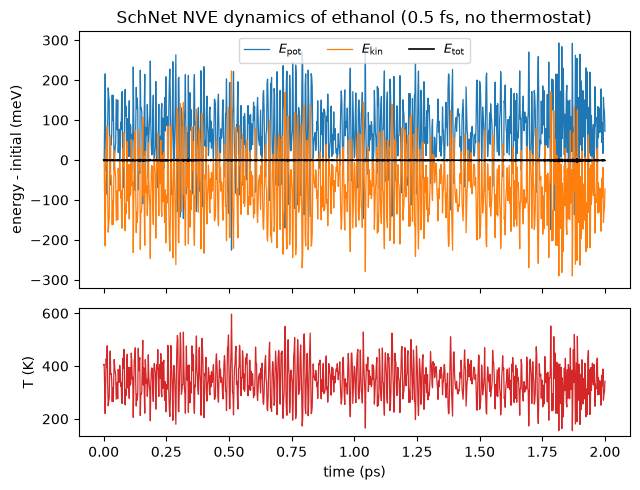

In [4]:
# Fit a line to the dynamics data to determine the energy drift (in meV/ps)
drift = np.polyfit(t_ps, (e_tot - e_tot[0]) * 1e3, 1)[0]

# Print the results
print(f"potential-energy fluctuation : {e_pot.std()*1e3:8.2f} meV")
print(f"total-energy fluctuation     : {e_tot.std()*1e3:8.3f} meV")
print(f"total-energy drift           : {drift:8.3f} meV/ps")
print(f"conservation ratio  std(E_tot)/std(E_pot) = "
      f"{e_tot.std()/e_pot.std():.4f}")

# Plot the NVE dynamics data
fig, (a1, a2) = plt.subplots(2, 1, figsize=(6.5, 5), sharex=True,
                             height_ratios=[2, 1])
a1.plot(t_ps, (e_pot - e_pot[0]) * 1e3, label=r"$E_\mathrm{pot}$", lw=0.9)
a1.plot(t_ps, (e_kin - e_kin[0]) * 1e3, label=r"$E_\mathrm{kin}$", lw=0.9)
a1.plot(t_ps, (e_tot - e_tot[0]) * 1e3, "k", label=r"$E_\mathrm{tot}$", lw=1.2)
a1.set_ylabel("energy - initial (meV)")
a1.set_title("SchNet NVE dynamics of ethanol (0.5 fs, no thermostat)")
a1.legend(ncols=3, fontsize=9)
a2.plot(t_ps, temp, lw=0.9, color="tab:red")
a2.set_xlabel("time (ps)")
a2.set_ylabel("T (K)")
fig.tight_layout()
fig.savefig("schnet_nve_energy.png", dpi=110)
plt.show()

## Summary

Kinetic and potential energy exchange on the 100 meV scale while the total
energy fluctuates by under a meV (about 1% of the potential-energy
fluctuation) with no systematic drift over 2 ps of thermostat-free dynamics.
Thus, the resulting atomic forces of SchNet, computed by the autograd are
conservative to integration accuracy as guaranteed by construction.

## References

- [Schütt et al., *SchNet: A continuous-filter convolutional neural network for modeling quantum interactions* arXiv.1706.08566 (2017)](https://arxiv.org/pdf/1706.08566)
- [Schütt et al., *SchNet: A deep learning architecture for molecules and materials*, J. Chem. Phys. 148, 241722 (2018)](https://doi.org/10.1063/1.5019779)